Original Dataset:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647            

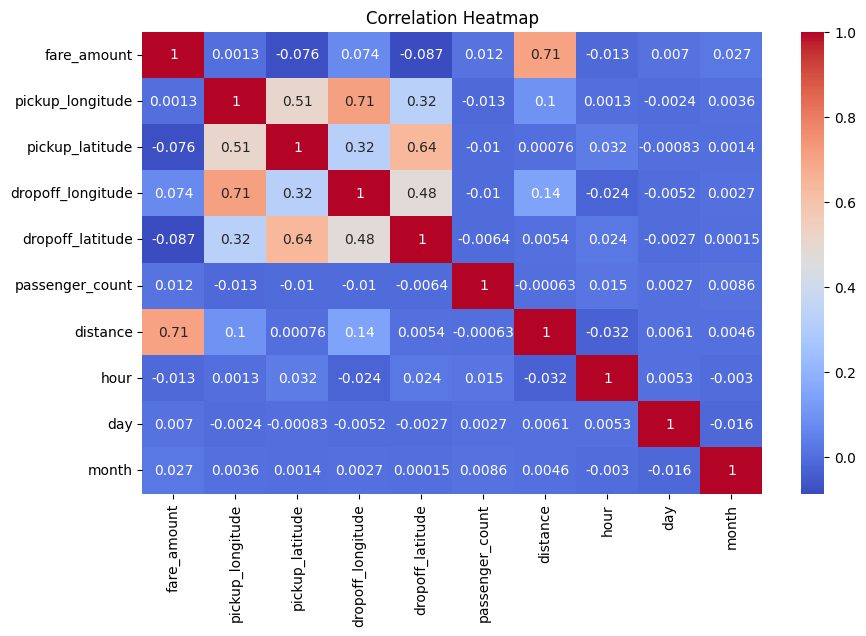

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Dataset
df = pd.read_csv("/kaggle/input/datasets/yasserh/uber-fares-dataset/uber.csv")

print("Original Dataset:")
print(df.head())

# 2. Pre-processing
df = df.drop(columns=["key", "Unnamed: 0"], errors="ignore")

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df = df.dropna()

# Remove invalid values
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42))
].copy()

# Calculate distance using Haversine formula
def distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = distance(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

# Extract time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

df = df.drop(columns=["pickup_datetime"])

# 3. Identify and Remove Outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["fare_amount"] < lower) |
              (df["fare_amount"] > upper)]

print("\nNumber of Outliers:", len(outliers))

df = df[(df["fare_amount"] >= lower) &
        (df["fare_amount"] <= upper)]

# 4. Check Correlation
print("\nCorrelation Matrix:")
print(df.corr(numeric_only=True))

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [2]:
# 5. Split Data
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

# 7. Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

# 8. Model Evaluation
def evaluate(name, actual, predicted):
    print("\n", name)
    print("MAE:", mean_absolute_error(actual, predicted))
    print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
    print("R2 Score:", r2_score(actual, predicted))

evaluate("Linear Regression", y_test, y_pred_lr)
evaluate("Random Forest Regression", y_test, y_pred_rf)


 Linear Regression
MAE: 1.903902342919708
RMSE: 3.093613471840643
R2 Score: 0.4421435525946895

 Random Forest Regression
MAE: 1.5071077384455842
RMSE: 2.1434354498019523
R2 Score: 0.7321996289253194
